In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from Bio import SeqIO

In [ ]:
#Read in all Transposon Classification for the TU sequences and store in dict

#First read in the TE Classes predicted by TransposonUltimate (from gff and save in a dict)
gff = "/global/group/research/m_lebh01/TransposonUltimateTE/DmelDK/FinalAnnotations_Transposons.gff3"
TEClassDict = {}
with open(gff, "r") as TUClass:
    for line in TUClass:
        if not line.startswith("seq"):
            print("Skipped line")
            continue
        l = line.strip().split("\t")
        TE = "Transposon" + l[8].split(";")[0].split("=")[1].strip()
        Class = l[8].split(";")[1].split("(")[0].split("=")[1].split("/")[0]
        TEClassDict[TE] = [Class]

#Now read in DeepTE
deepTE = "opt_DeepTE.txt"
with open(deepTE, "r") as DT:
    for line in DT:
        l = line.strip().split()
        TE = l[0]
        Class = l[1].split("_")[0]
        if Class == "ClassI":
            Class = "1"
        elif Class == "ClassII":
            Class = "2"
        elif Class == "ClassIII":
            Class = "2"
        elif Class == "unknown":
            Class = "U"
        TEClassDict[TE].append(Class)

#Read in RepeatClassifier (only available as fasta)
from Bio import SeqIO
RC = SeqIO.to_dict(SeqIO.parse("FinalAnnotations_TransposonSequences.fasta.classified", "fasta"))

for key in RC:
    TE = key.split("#")[0]
    Class = key.split("#")[1].split()[0].split("/")[0]
    if Class == "LTR" or Class == "LINE" or Class == "SINE":
        Class = "1"
    elif Class == "DNA" or Class == "RC":
        Class = "2"
    elif Class == "Simple_repeat" or Class == "Low_Complexity" or Class == "Satellite" or Class == "rRNA" or Class == "tRNA":
        Class = "R"
    elif Class == "Unknown":
        Class = "U"
    else:
        print(Class)
    TEClassDict[TE].append(Class)

#TEClassDict now has the TE and all three predicted classes

In [ ]:
#Join the dictionary in a dataframe into a dataframe
df = (
    pd.DataFrame.from_dict(
        TEClassDict,
        orient='index',
        columns=['TransposonUltimate', 'DeepTE', 'RepeatClassifier']
    )
    .reset_index(names='id')
)

#Now make a column for each comparison (e.g. 1_1 would mean both tools predicted class I)
df["TU_DT"] = df["TransposonUltimate"] +"_" + df["DeepTE"]
df["TU_RC"] = df["TransposonUltimate"] +"_" + df["RepeatClassifier"]
df["RC_DT"] = df["RepeatClassifier"] +"_" + df["DeepTE"]
df["All"] = df["TransposonUltimate"] +"_" + df["RepeatClassifier"]+"_" + df["DeepTE"]


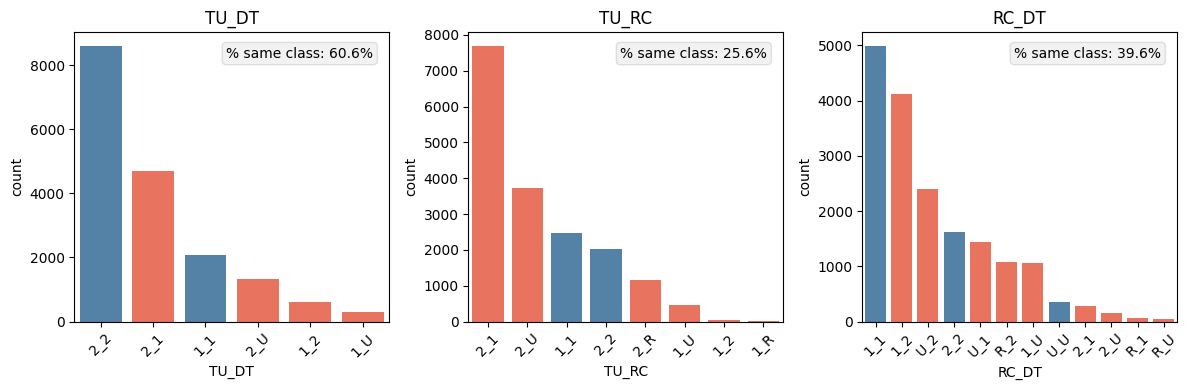

In [ ]:
#Now plot the agreement between the three
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

def agreement(x):
    a, b = x.split('_')
    return a == b  #This means both tools predicted the same thing

palette = {
    cat: ('steelblue' if agreement(cat) else 'tomato')
    for cat in pd.concat([df['TU_DT'], df['TU_RC'], df['RC_DT']]).unique()
}

for ax, col in zip(axes, ['TU_DT', 'TU_RC', 'RC_DT']):

    sns.countplot(
        data=df,
        x=col,
        hue=col,
        order=df[col].value_counts().index, #we want to order from highest to lowest count
        ax=ax,
        palette=palette
    )
    

    # agreement rate for this comparison
    agreement_rate = df[col].apply(agreement).mean()

    ax.text(
        0.95, 0.95,
        f'% same class: {agreement_rate:.1%}',
        transform=ax.transAxes,
        ha='right',
        va='top',
        bbox=dict(boxstyle='round', facecolor='grey', alpha=0.1)
    )

    ax.set_title(col)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig("TEClassificationDK_Comp.jpg")